# Eksploracja danych · Laboratorium 5
## Wykrywanie anomalii (spotkanie 2): LOF, porównanie metod, koszt decyzji, walidacja, dryf

Od tego spotkania funkcje są w module `anomalie.py` (projekt zaliczeniowy). Notatnik leży w katalogu projektu, obok `anomalie.py` i `dane/`.
Najpierw uzupełnij funkcje z TODO i uruchom `pytest -q` w terminalu.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import anomalie as A

S = A.dodaj_cechy(A.wczytaj("dane/dostawy_styczen.csv"))
L = A.dodaj_cechy(A.wczytaj("dane/dostawy_luty.csv"))
M = A.dodaj_cechy(A.wczytaj("dane/dostawy_marzec.csv"))
y = S.etykieta.to_numpy()
BUDZET = 60
pd.set_option("display.precision", 4)

def r(m):
    """Metryki do wydruku: liczby zaokrąglone do 4 miejsc."""
    return {k: (int(v) if k in ("alarmy", "TP", "FP", "FN", "TN", "koszt") else round(float(v), 4)) for k, v in m.items()}

## Z1. LOF i porównanie pięciu metod przy tym samym budżecie alarmów

In [2]:
mk = A.model_kosztu(S)
norma = A.norma_reguly(S, mk)
X, skaler = A.macierz_cech(S)
W = {
    "IQR koszt": S.koszt_pln.to_numpy(),
    "Model normy": A.wynik_reguly(S, mk, norma).to_numpy(),
    "K-means": A.wynik_kmeans(X, 5)[0],
    "Isolation Forest": A.wynik_isolation_forest(X)[0],
    "LOF": A.wynik_lof(X, 20),
}
tab = pd.DataFrame({k: r(A.metryki(y, A.alarm_top(v, BUDZET))) for k, v in W.items()}).T
tab

Out[2]: 
                  alarmy    TP    FP    FN  ...  precision  recall      F1    koszt
IQR koszt           60.0  22.0  38.0  23.0  ...     0.3667  0.4889  0.4190  19900.0
Model normy         60.0  45.0  15.0   0.0  ...     0.7500  1.0000  0.8571   1500.0
K-means             60.0  17.0  43.0  28.0  ...     0.2833  0.3778  0.3238  23900.0
Isolation Forest    60.0  20.0  40.0  25.0  ...     0.3333  0.4444  0.3810  21500.0
LOF                 60.0  37.0  23.0   8.0  ...     0.6167  0.8222  0.7048   7900.0

[5 rows x 9 columns]


In [3]:
typy = pd.DataFrame({k: A.recall_wg_typu(S, A.alarm_top(v, BUDZET)) for k, v in W.items()}).T
typy

Out[3]: 
typ_anomalii      koszt +1600 zł  koszt ×3,5  opóźnienie +35 h
IQR koszt                 0.5333      0.9333            0.0000
Model normy               1.0000      1.0000            1.0000
K-means                   0.1333      0.9333            0.0667
Isolation Forest          0.1333      0.3333            0.8667
LOF                       0.9333      0.5333            1.0000


**Pytania:** (1) Która metoda wygrywa i dlaczego (pomyśl o tym, co wie o procesie)? (2) Dlaczego LOF łapie „koszt +1600 zł” lepiej niż Isolation Forest?

*Odpowiedź:* Model normy: 45 TP, precision 0,75, recall 1,00, F1 0,8571. Uwzględnia odległość, masę, ekspres, sobotę i typowe opóźnienie danego dnia. LOF wykrywa lokalne odstępstwa: dopłata +1600 zł wyróżnia dostawę na tle podobnych tras nawet wtedy, gdy jej koszt nie jest globalnie skrajny. LOF wykrywa 14/15 takich dopłat, 8/15 mnożników kosztu i 15/15 opóźnień.

## Z2. Ile alarmów sprawdzać? Krzywa kosztu

IQR koszt          najniższy koszt    14900 zł przy 116 alarmach (TP = 30)
Model normy        najniższy koszt     1125 zł przy 45 alarmach (TP = 45)
K-means            najniższy koszt    10775 zł przy 335 alarmach (TP = 42)
Isolation Forest   najniższy koszt    12400 zł przy 240 alarmach (TP = 37)
LOF                najniższy koszt     3275 zł przy 131 alarmach (TP = 45)


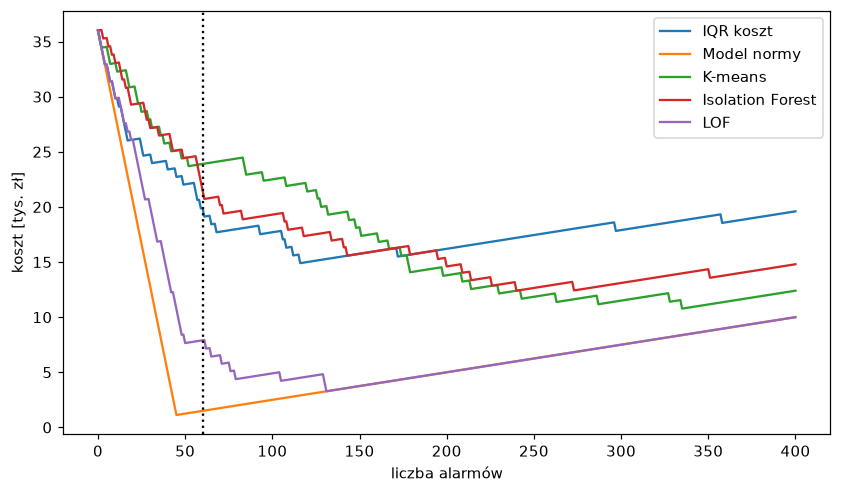

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
for k, v in W.items():
    c = A.krzywa_kosztu(v, y, n_max=400)
    ax.plot(c.alarmy, c.koszt / 1000, label=k)
    i = c.koszt.idxmin()
    print(f"{k:18s} najniższy koszt {c.koszt[i]:8.0f} zł przy {int(c.alarmy[i])} alarmach (TP = {int(c.TP[i])})")
ax.axvline(BUDZET, ls=":", color="k"); ax.set_xlabel("liczba alarmów"); ax.set_ylabel("koszt [tys. zł]"); ax.legend(); plt.show()

**Pytanie:** krzywą policzyliśmy z etykietami. Dlaczego „optymalna liczba alarmów” ze stycznia to optymistyczne oszacowanie i jak to sprawdzić?

*Odpowiedź:* Minimum krzywej to retrospektywna analiza z użyciem etykiet tego samego zbioru, więc jest optymistyczne i nie stanowi dozwolonego sposobu wyboru progu w tym zadaniu. Próg operacyjny ustalamy bez etykiet: wynik 60. dostawy w styczniu. Zamrażamy modele, skaler i normę, a następnie oceniamy wyniki na lutym. Do niezależnego potwierdzenia decyzji podjętych po obejrzeniu lutego potrzebny byłby kolejny okres.

## Z3. Walidacja na lutym: modele, skaler i progi ze stycznia

In [5]:
XL, _ = A.macierz_cech(L, skaler=skaler)
km_model = A.wynik_kmeans(X, 5)[1]; if_model = A.wynik_isolation_forest(X)[1]
WL = {
    "IQR koszt": L.koszt_pln.to_numpy(),
    "Model normy": A.wynik_reguly(L, mk, norma).to_numpy(),
    "K-means": A.wynik_kmeans(XL, model=km_model)[0],
    "Isolation Forest": A.wynik_isolation_forest(XL, model=if_model)[0],
    "LOF": A.wynik_lof(XL, 20, X_uczenie=X),
}
wal = {}
for k in W:
    prog = np.sort(W[k])[::-1][BUDZET - 1]          # próg = wynik 60. dostawy w styczniu
    wal[k] = r(A.metryki(L.etykieta, A.alarm_prog(WL[k], prog - 1e-9)))
pd.DataFrame(wal).T

Out[5]: 
                  alarmy    TP    FP    FN  ...  precision  recall      F1    koszt
IQR koszt           62.0  19.0  43.0  26.0  ...     0.3065  0.4222  0.3551  22350.0
Model normy         57.0  45.0  12.0   0.0  ...     0.7895  1.0000  0.8824   1425.0
K-means             68.0  13.0  55.0  32.0  ...     0.1912  0.2889  0.2301  27300.0
Isolation Forest    64.0  10.0  54.0  35.0  ...     0.1562  0.2222  0.1835  29600.0
LOF                 51.0  34.0  17.0  11.0  ...     0.6667  0.7556  0.7083  10075.0

[5 rows x 9 columns]


In [6]:
print("Model normy, stały próg z > 3,5:", r(A.metryki(L.etykieta, WL["Model normy"] > 3.5)))

Model normy, stały próg z > 3,5: {'alarmy': 112, 'TP': 45, 'FP': 67, 'FN': 0, 'TN': 1388, 'precision': 0.4018, 'recall': 1.0, 'F1': 0.5732, 'koszt': 2800}


## Z4. Marzec: nowy cennik od 16.03 (dryf procesu)

alarmów dziennie przed 16.03: 4.75  po: 15.57
przed: {'alarmy': 57, 'TP': 21, 'FP': 36, 'FN': 0, 'TN': 641, 'precision': 0.3684, 'recall': 1.0, 'F1': 0.5385, 'koszt': 1425}
po:    {'alarmy': 218, 'TP': 24, 'FP': 194, 'FN': 0, 'TN': 584, 'precision': 0.1101, 'recall': 1.0, 'F1': 0.1983, 'koszt': 5450}


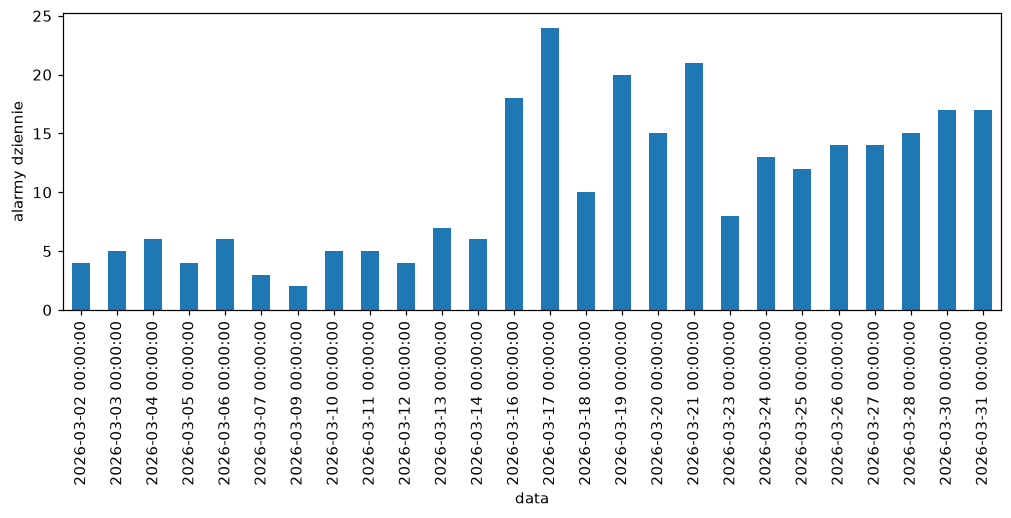

In [7]:
M["alarm"] = (A.wynik_reguly(M, mk, norma) > 3.5).to_numpy()
po = (M.data >= "2026-03-16").to_numpy()
dzien = M.groupby("data").alarm.sum()
print("alarmów dziennie przed 16.03:", round(dzien[dzien.index < "2026-03-16"].mean(), 2), " po:", round(dzien[dzien.index >= "2026-03-16"].mean(), 2))
print("przed:", r(A.metryki(M.etykieta[~po], M.alarm[~po])))
print("po:   ", r(A.metryki(M.etykieta[po], M.alarm[po])))
dzien.plot(kind="bar", figsize=(11, 3.5)); plt.ylabel("alarmy dziennie"); plt.show()

In [8]:
M["km_po_podwyzce"] = M.odleglosc_km * po          # stawka za km zmienia się od 16.03
mkM = A.model_kosztu(M, A.CECHY_MODELU + ["km_po_podwyzce"])
print("stawka za km przed:", round(mkM.coef_[0], 3), " dodatek po 16.03:", round(mkM.coef_[-1], 3))
M["alarm2"] = (A.wynik_reguly(M, mkM, A.norma_reguly(M, mkM)) > 3.5).to_numpy()
d2 = M.groupby("data").alarm2.sum()
print("po aktualizacji modelu: alarmów dziennie po 16.03:", round(d2[d2.index >= "2026-03-16"].mean(), 2))
print("po 16.03:", r(A.metryki(M.etykieta[po], M.alarm2[po])))

stawka za km przed: 1.967  dodatek po 16.03: 0.686
po aktualizacji modelu: alarmów dziennie po 16.03: 5.5
po 16.03: {'alarmy': 77, 'TP': 24, 'FP': 53, 'FN': 0, 'TN': 725, 'precision': 0.3117, 'recall': 1.0, 'F1': 0.4752, 'koszt': 1925}


**Pytania:** (1) Czy model „wykrył zmianę procesu”? Czym różni się alarm dla pojedynczej dostawy od sygnału, że zmieniła się norma? (2) Jak często aktualizować model i kto powinien o tym zdecydować?

*Odpowiedź:* Po 16.03 liczba alarmów rośnie z 4,75 do 15,57 dziennie, a F1 spada do 0,1983. To sygnał zmiany normy kosztu, nie dowód wielu nowych błędnych dostaw. Potwierdzamy zmianę cennika u przewoźnika i w dziale zakupów. Dodatek ok. 0,69 zł/km obniża liczbę alarmów do 5,50 dziennie, F1 rośnie do 0,4752. Monitorowanie powinno być codzienne, przegląd modelu miesięczny i po potwierdzonej zmianie cennika; decyzję zatwierdza właściciel procesu wraz z rozliczeniami i analitykiem. Model aktualizowany na całym marcu jest demonstracją retrospektywną, a nie niezależną walidacją; w praktyce sprawdzamy go na późniejszych danych. Mediana dnia wymaga zakończonego dnia: to analiza wsadowa, nie alarmowanie na żywo.

## Z5. Projekt: testy, dashboard, GitHub, Render

W terminalu, w katalogu projektu:
```
pytest -q
streamlit run app.py
```
Potem kroki z `README.md`: repozytorium na GitHubie, wdrożenie na Render. Do README dopisz tabelę z Z1 (budżet 60), trzy wnioski ekonomiczne i jedno ograniczenie analizy.